# Pipeline avanzado: pronóstico del consumo eléctrico diario con redes recurrentes

Unidad 4, actividad evaluativa 2. Técnicas avanzadas de modelado de IA.

Integrantes: Saud Mauricio González Rodríguez.

Este notebook continúa el plan experimental de la actividad 1. Usa el mismo dataset de UCI (consumo eléctrico de un hogar en Sceaux, Francia), la misma imputación, las mismas particiones cronológicas y las mismas métricas. Aquí se implementan redes LSTM, GRU y convolucionales en PyTorch, se hacen experimentos controlados sobre los hiperparámetros, se registran en MLflow y se compara el modelo elegido con la línea base.

In [1]:
import os, json, time, hashlib, random, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib
import matplotlib.pyplot as plt
os.environ.setdefault('MLFLOW_ALLOW_FILE_STORE', 'true'); os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
import mlflow

RUTA_DATOS = os.environ.get('RUTA_DATOS', '/home/claude/data/household_power_consumption.txt')
HUELLA = '4259c9d7ece5dbee'
EJECUTAR_BUSQUEDA = os.environ.get('EJECUTAR_BUSQUEDA', '0') == '1'   # la búsqueda completa tarda; por defecto se leen sus resultados guardados
SALIDA = os.environ.get('SALIDA', 'resultados')
os.makedirs(SALIDA, exist_ok=True)
torch.set_num_threads(max(1, os.cpu_count() or 1))
torch.set_flush_denormal(True)   # evita números desnormales en la retropropagación de la LSTM, que hacían el entrenamiento 7 veces más lento en CPU
mlflow.set_tracking_uri('file:' + os.path.abspath('mlruns'))
mlflow.set_experiment('consumo_diario_u4a2')
print('torch', torch.__version__, '| mlflow', mlflow.__version__)

def fijar_semilla(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.use_deterministic_algorithms(True, warn_only=True)

torch 2.14.1 | mlflow 3.17.2


## 1. Datos, imputación y particiones

Se repite el preprocesamiento de la actividad 1: se verifica la huella del archivo, los vacíos se llenan con el mismo minuto de semanas anteriores (solo pasado) y se agrega a nivel horario. El objetivo es la energía del día siguiente en kWh. Las fechas de corte son las mismas del plan y no se cambian.

In [2]:
assert hashlib.sha256(open(RUTA_DATOS, 'rb').read()).hexdigest().startswith(HUELLA), 'archivo distinto al documentado'
raw = pd.read_csv(RUTA_DATOS, sep=';', na_values='?', low_memory=False)
raw.index = pd.to_datetime(raw['Date'] + ' ' + raw['Time'], format='%d/%m/%Y %H:%M:%S')
raw = raw.drop(columns=['Date', 'Time']).sort_index()
imp = raw.copy()
for k in range(1, 5):
    imp = imp.fillna(raw.shift(7 * 1440 * k, freq='min').reindex(raw.index))
imp = imp.interpolate(limit=60)
assert imp.isna().sum().sum() == 0
horaria = imp.resample('h').mean().loc['2006-12-17':'2010-11-25 23:00']
diaria = (imp['Global_active_power'].resample('D').mean() * 24).loc['2006-12-17':'2010-11-25'].rename('kwh')
CORTES = {'train': ('2006-12-17', '2009-06-30'), 'val': ('2009-07-01', '2009-12-31'), 'test': ('2010-01-01', '2010-11-25')}
print(horaria.shape, diaria.shape)

(34560, 7) (1440,)


Cada muestra usa una ventana de días previos a resolución horaria con las siete variables medidas, más el calendario del día a pronosticar (día de la semana y mes) y la media de los siete días previos. Las medias y desviaciones para normalizar se calculan solo con el bloque de entrenamiento.

In [3]:
VARS = list(horaria.columns)
mask_tr_h = horaria.index <= pd.Timestamp(CORTES['train'][1] + ' 23:00')
mu_x, sd_x = horaria[mask_tr_h].mean().values, horaria[mask_tr_h].std().values
Xh = ((horaria.values - mu_x) / sd_x).astype(np.float32).reshape(len(diaria), 24, len(VARS))
y = diaria.values.astype(np.float32)
media7 = diaria.shift(1).rolling(7).mean().values.astype(np.float32)
dias = diaria.index
cal = np.concatenate([np.eye(7)[dias.dayofweek],
                      np.c_[np.sin(2 * np.pi * dias.month / 12), np.cos(2 * np.pi * dias.month / 12)]], axis=1).astype(np.float32)
mask_tr_d = dias <= pd.Timestamp(CORTES['train'][1])
mu_y, sd_y = float(y[mask_tr_d].mean()), float(y[mask_tr_d].std())

def construir(ventana):
    idx = np.arange(max(ventana, 7), len(dias))
    X = np.stack([Xh[i - ventana:i].reshape(ventana * 24, len(VARS)) for i in idx])
    C = np.c_[cal[idx], ((media7[idx] - mu_y) / sd_y)[:, None]].astype(np.float32)
    return idx, X, C

def bloque(idx, nombre):
    a, b = CORTES[nombre]
    return (dias[idx] >= pd.Timestamp(a)) & (dias[idx] <= pd.Timestamp(b))

/tmp/ipykernel_3991/1173475433.py:8: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  cal = np.concatenate([np.eye(7)[dias.dayofweek],


## 2. Arquitecturas

La red principal es una LSTM. La entrada horaria pasa por capas recurrentes que resumen la ventana en un vector oculto; ese vector se une con el calendario y la media de la semana previa, y una pequeña capa densa entrega el pronóstico. La LSTM se eligió porque sus compuertas permiten conservar información de varios días atrás (el patrón semanal) sin que el gradiente se desvanezca, como explican Goodfellow, Bengio y Courville en el capítulo 10. Se comparan una GRU, que tiene menos parámetros, y una red convolucional de una dimensión, que aplica la idea de convolución del material del curso sobre el eje del tiempo.

El modelo puede predecir el consumo directamente o predecir la corrección sobre la media de los siete días previos (modo residual). En el modo residual la red parte de la mejor línea base y solo tiene que aprender lo que esta no explica.

In [4]:
class Recurrente(nn.Module):
    def __init__(self, tipo, n_in, oculto, capas, dropout, n_cal):
        super().__init__()
        rnn = nn.LSTM if tipo == 'lstm' else nn.GRU
        self.rnn = rnn(n_in, oculto, num_layers=capas, batch_first=True, dropout=dropout if capas > 1 else 0.0)
        self.cabeza = nn.Sequential(nn.Linear(oculto + n_cal, 32), nn.ReLU(), nn.Dropout(dropout), nn.Linear(32, 1))
    def forward(self, x, c):
        _, h = self.rnn(x)
        h = h[0] if isinstance(h, tuple) else h
        return self.cabeza(torch.cat([h[-1], c], dim=1)).squeeze(1)

class Convolucional(nn.Module):
    def __init__(self, n_in, oculto, dropout, n_cal):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv1d(n_in, oculto, 5, padding=2), nn.ReLU(), nn.MaxPool1d(4),
                                  nn.Conv1d(oculto, oculto, 5, padding=2), nn.ReLU(), nn.MaxPool1d(4),
                                  nn.Conv1d(oculto, oculto, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool1d(1))
        self.cabeza = nn.Sequential(nn.Linear(oculto + n_cal, 32), nn.ReLU(), nn.Dropout(dropout), nn.Linear(32, 1))
    def forward(self, x, c):
        z = self.conv(x.transpose(1, 2)).squeeze(2)
        return self.cabeza(torch.cat([z, c], dim=1)).squeeze(1)

BASE = dict(arq='lstm', oculto=64, capas=2, dropout=0.2, lr=1e-3, opt='adam', wd=0.0, ventana=14,
            residual=False, lote=32, epocas=100, paciencia=15)

def crear_modelo(cfg, n_cal):
    if cfg['arq'] == 'cnn':
        return Convolucional(len(VARS), cfg['oculto'], cfg['dropout'], n_cal)
    return Recurrente(cfg['arq'], len(VARS), cfg['oculto'], cfg['capas'], cfg['dropout'], n_cal)

def crear_opt(cfg, params):
    if cfg['opt'] == 'adam':    return torch.optim.Adam(params, lr=cfg['lr'], weight_decay=cfg['wd'])
    if cfg['opt'] == 'adamw':   return torch.optim.AdamW(params, lr=cfg['lr'], weight_decay=cfg['wd'])
    if cfg['opt'] == 'rmsprop': return torch.optim.RMSprop(params, lr=cfg['lr'], weight_decay=cfg['wd'])
    if cfg['opt'] == 'sgd':     return torch.optim.SGD(params, lr=cfg['lr'], momentum=0.9, weight_decay=cfg['wd'])

## 3. Entrenamiento con parada temprana y registro en MLflow

La pérdida es el error absoluto medio, la misma métrica principal del plan. Se entrena solo con el bloque de entrenamiento; el bloque de validación decide la parada temprana y se restauran los pesos de la mejor época. En cada época se guarda la pérdida de entrenamiento y la de validación en kWh para dibujar las curvas. Cada corrida se registra en MLflow con sus parámetros, métricas por época y la semilla.

In [5]:
DATOS = {}
def datos(ventana):
    if ventana not in DATOS:
        idx, X, C = construir(ventana)
        DATOS[ventana] = dict(idx=idx, X=torch.from_numpy(X), C=torch.from_numpy(C),
                              y=torch.from_numpy((y[idx] - mu_y) / sd_y), m7=torch.from_numpy((media7[idx] - mu_y) / sd_y),
                              tr=bloque(idx, 'train'), va=bloque(idx, 'val'), te=bloque(idx, 'test'))
    return DATOS[ventana]

def predecir(modelo, D, mask, cfg):
    modelo.eval()
    with torch.no_grad():
        p = modelo(D['X'][mask], D['C'][mask])
        if cfg['residual']: p = p + D['m7'][mask]
    return p.numpy() * sd_y + mu_y

def entrenar(cfg, semilla, nombre=None, registrar=True):
    fijar_semilla(semilla)
    D = datos(cfg['ventana'])
    modelo = crear_modelo(cfg, D['C'].shape[1]); opt = crear_opt(cfg, modelo.parameters())
    tr = np.where(D['tr'])[0]; yv = y[D['idx'][D['va']]]
    objetivo = D['y'] - D['m7'] if cfg['residual'] else D['y']
    hist, mejor, sin_mejora, estado = [], np.inf, 0, None
    gen = np.random.default_rng(semilla); t0 = time.time()
    for ep in range(cfg['epocas']):
        modelo.train(); gen.shuffle(tr); perdidas = []
        for i in range(0, len(tr), cfg['lote']):
            b = tr[i:i + cfg['lote']]
            loss = nn.functional.l1_loss(modelo(D['X'][b], D['C'][b]), objetivo[b])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(modelo.parameters(), 1.0); opt.step()
            perdidas.append(loss.item() * len(b))
        mae_tr = sum(perdidas) / len(tr) * sd_y
        mae_va = float(np.mean(np.abs(predecir(modelo, D, D['va'], cfg) - yv)))
        hist.append((ep + 1, mae_tr, mae_va))
        if mae_va < mejor - 1e-4: mejor, sin_mejora, estado, mejor_ep = mae_va, 0, copy.deepcopy(modelo.state_dict()), ep + 1
        else: sin_mejora += 1
        if sin_mejora >= cfg['paciencia']: break
    modelo.load_state_dict(estado)
    res = dict(mae_val=mejor, mejor_epoca=mejor_ep, epocas=len(hist), segundos=time.time() - t0,
               parametros=sum(p.numel() for p in modelo.parameters()))
    if registrar:
        with mlflow.start_run(run_name=nombre):
            mlflow.log_params({**cfg, 'semilla': semilla})
            for ep, a, b in hist: mlflow.log_metrics({'mae_train': a, 'mae_val': b}, step=ep)
            mlflow.log_metrics({k: v for k, v in res.items()})
    return modelo, hist, res

## 4. Experimentos controlados

Siguiendo el enfoque científico de la guía de ajuste de Google, cada etapa cambia un solo factor y deja fijo el resto en el valor elegido hasta ese momento. El valor actual solo se reemplaza si el nuevo baja el MAE medio de validación en más del error estándar de la diferencia, que es la raíz de (s1² + s2²)/3 con las desviaciones entre las tres semillas; si la diferencia es menor, se considera ruido y se conserva el valor actual, que además suele ser el más barato de entrenar. Cada configuración se corre con tres semillas y se reporta la media y la desviación del MAE de validación, para no confundir una mejora real con el azar de la inicialización. El conjunto de prueba no se usa en ninguna de estas decisiones.

In [6]:
ETAPAS = [
    ('tasa de aprendizaje', 'lr', [3e-3, 1e-3, 3e-4, 1e-4]),
    ('optimizador', 'opt', [('adam', 0.0), ('adamw', 1e-2), ('rmsprop', 0.0), ('sgd', 0.0)]),
    ('dropout', 'dropout', [0.0, 0.2, 0.4]),
    ('decaimiento de pesos', 'wd', [0.0, 1e-4, 1e-3]),
    ('formulación del objetivo', 'residual', [False, True]),
    ('arquitectura', 'arq', ['lstm', 'gru', 'cnn']),
    ('tamaño oculto', 'oculto', [32, 64, 128]),
    ('ventana de días', 'ventana', [7, 14, 28]),
]
SEMILLAS = [11, 22, 33]

def aplicar(cfg, clave, valor):
    c = dict(cfg)
    if clave == 'opt':
        c['opt'], c['wd'] = valor
        if valor[0] == 'sgd': c['lr'] = max(c['lr'] * 10, 1e-2)   # SGD necesita pasos más grandes que Adam
    else:
        c[clave] = valor
    return c

if EJECUTAR_BUSQUEDA:
    ruta_cache = f'{SALIDA}/cache_corridas.json'
    cache = json.load(open(ruta_cache)) if os.path.exists(ruta_cache) else {}
    cfg_actual, filas, curvas = dict(BASE), [], {}
    for etapa, clave, valores in ETAPAS:
        for v in valores:
            c = aplicar(cfg_actual, clave, v)
            for s in SEMILLAS:
                clave_cache = json.dumps(c, sort_keys=True) + str(s)
                if clave_cache in cache:
                    hist, r = cache[clave_cache]
                else:
                    _, hist, r = entrenar(c, s, nombre=f'{etapa}={v}|s{s}'); cache[clave_cache] = (hist, r)
                    json.dump(cache, open(ruta_cache, 'w'))
                filas.append(dict(etapa=etapa, valor=str(v), semilla=s, cfg=json.dumps(c), **r))
                curvas[f'{etapa}={v}|s{s}'] = hist
                print(etapa, v, s, round(r['mae_val'], 3), r['mejor_epoca'], round(r['segundos'], 1), flush=True)
        tab = pd.DataFrame([f for f in filas if f['etapa'] == etapa]).groupby('valor')['mae_val'].agg(['mean', 'std'])
        mejor_v = tab['mean'].idxmin()
        actual_v = str((cfg_actual['opt'], cfg_actual['wd']) if clave == 'opt' else cfg_actual[clave])
        # regla de decisión: solo se cambia el valor actual si la mejora supera el error estándar de la diferencia de medias
        if actual_v in tab.index:
            ee = np.sqrt((tab.loc[actual_v, 'std'] ** 2 + tab.loc[mejor_v, 'std'] ** 2) / len(SEMILLAS))
            if tab.loc[actual_v, 'mean'] - tab.loc[mejor_v, 'mean'] <= ee:
                mejor_v = actual_v
        cfg_actual = json.loads([f['cfg'] for f in filas if f['etapa'] == etapa and f['valor'] == mejor_v][0])
        print('>> etapa', etapa, 'elegido', mejor_v, tab.round(3).to_dict(), flush=True)
    pd.DataFrame(filas).to_csv(f'{SALIDA}/experimentos.csv', index=False)
    json.dump(curvas, open(f'{SALIDA}/curvas.json', 'w'))
    json.dump(cfg_actual, open(f'{SALIDA}/cfg_final.json', 'w'), indent=1)

exp = pd.read_csv(f'{SALIDA}/experimentos.csv'); curvas = json.load(open(f'{SALIDA}/curvas.json'))
CFG = json.load(open(f'{SALIDA}/cfg_final.json'))
resumen = (exp.groupby(['etapa', 'valor'], sort=False)
              .agg(mae_val_media=('mae_val', 'mean'), mae_val_desv=('mae_val', 'std'),
                   mejor_epoca=('mejor_epoca', 'mean'), segundos=('segundos', 'mean'), parametros=('parametros', 'first'))
              .round(3).reset_index())
resumen.to_csv(f'{SALIDA}/resumen_experimentos.csv', index=False)
print(resumen.to_string(index=False)); print('Configuración elegida en validación:', CFG)

                   etapa            valor  mae_val_media  mae_val_desv  mejor_epoca  segundos  parametros
     tasa de aprendizaje            0.003          3.642         0.060        8.333    41.715       54401
     tasa de aprendizaje            0.001          3.647         0.051       16.667    58.968       54401
     tasa de aprendizaje           0.0003          3.640         0.018       31.667    90.453       54401
     tasa de aprendizaje           0.0001          3.621         0.014       94.333   204.939       54401
             optimizador    ('adam', 0.0)          3.647         0.051       16.667    58.968       54401
             optimizador  ('adamw', 0.01)          3.626         0.053       15.000    63.374       54401
             optimizador ('rmsprop', 0.0)          3.617         0.031       11.333    56.379       54401
             optimizador     ('sgd', 0.0)          3.652         0.146       42.333   108.678       54401
                 dropout              0.0     

## 5. Curvas de aprendizaje

Se grafican el MAE de entrenamiento y el de validación por época para las variantes que más informan sobre el diagnóstico: tasa de aprendizaje alta y baja, sin dropout y con dropout, la red convolucional y la configuración final. La línea vertical marca la época que eligió la parada temprana. El MAE de entrenamiento de estas curvas se mide durante la época, con dropout activo y mientras los pesos cambian, así que tiende a verse más alto que el real; en la sección 6 se mide también sin dropout.

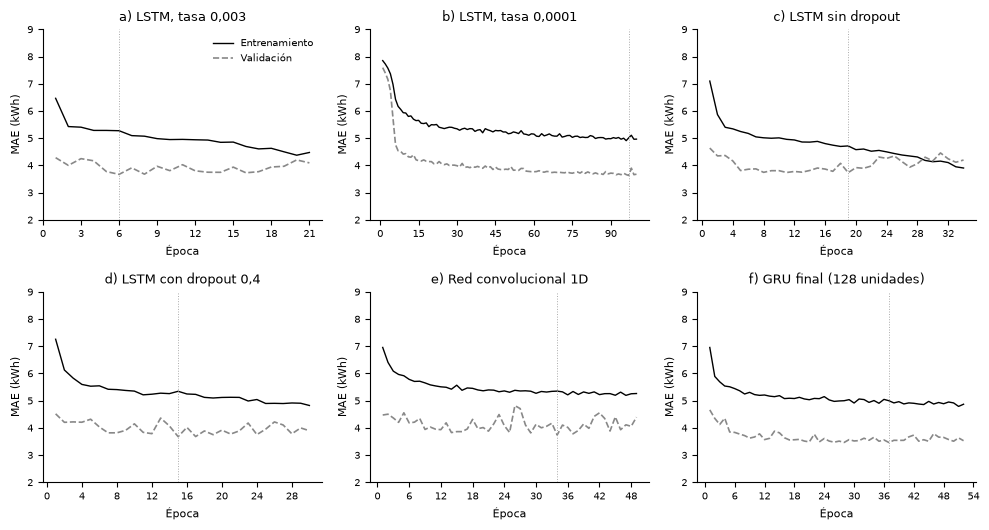

In [7]:
from matplotlib.ticker import MaxNLocator
def curva(ax, clave, titulo):
    h = np.array(curvas[clave]); ax.plot(h[:, 0], h[:, 1], label='Entrenamiento', color='black', lw=1)
    ax.plot(h[:, 0], h[:, 2], label='Validación', color='#888888', lw=1.2, ls='--')
    ax.axvline(h[np.argmin(h[:, 2]), 0], color='#aaaaaa', lw=0.7, ls=':')
    ax.set_title(titulo, fontsize=9); ax.set_xlabel('Época', fontsize=8); ax.set_ylabel('MAE (kWh)', fontsize=8)
    ax.set_ylim(2, 9); ax.tick_params(labelsize=7); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.spines.top': False, 'axes.spines.right': False})
fig, axs = plt.subplots(2, 3, figsize=(10, 5.4))
curva(axs[0, 0], 'tasa de aprendizaje=0.003|s11', 'a) LSTM, tasa 0,003')
curva(axs[0, 1], 'tasa de aprendizaje=0.0001|s11', 'b) LSTM, tasa 0,0001')
curva(axs[0, 2], 'dropout=0.0|s11', 'c) LSTM sin dropout')
curva(axs[1, 0], 'dropout=0.4|s11', 'd) LSTM con dropout 0,4')
curva(axs[1, 1], 'arquitectura=cnn|s11', 'e) Red convolucional 1D')
curva(axs[1, 2], 'ventana de días=14|s11', 'f) GRU final (128 unidades)')
axs[0, 0].legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(f'{SALIDA}/fig_curvas.png', dpi=200); plt.show()

## 6. Modelo final y evaluación en prueba

Con la configuración elegida en validación se entrenan cinco modelos con semillas distintas. Se reporta el MAE de cada uno y el del promedio de los cinco (ensamble por semillas). Solo en este punto se usa el conjunto de prueba.

 semilla  mae_train_sin_dropout  mae_val  mae_test  epoca  segundos
     101                  4.794    3.428     4.107     34   404.883
     202                  4.772    3.455     4.158     39   463.369
     303                  4.886    3.510     4.118     27   351.109
     404                  4.928    3.561     4.085     20   288.105
     505                  4.903    3.484     4.174     26   349.145
Desviación de y en entrenamiento, validación y prueba: [10.38, 8.91, 8.25]


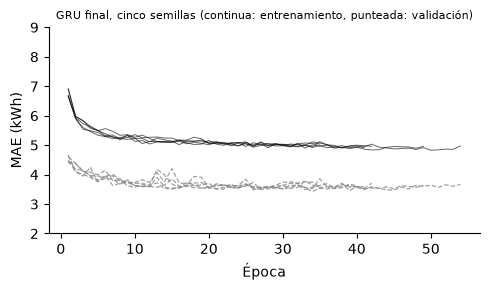

In [8]:
SEMILLAS_FINALES = [101, 202, 303, 404, 505]
D = datos(CFG['ventana']); fechas_te = dias[D['idx'][D['te']]]; yt = y[D['idx'][D['te']]]
preds, curvas_fin, info = [], {}, []
for s in SEMILLAS_FINALES:
    m, hist, r = entrenar(CFG, s, nombre=f'final|s{s}')
    p = predecir(m, D, D['te'], CFG); preds.append(p); curvas_fin[s] = hist
    ytr = y[D['idx'][D['tr']]]
    mae_tr_eval = float(np.mean(np.abs(predecir(m, D, D['tr'], CFG) - ytr)))   # entrenamiento medido sin dropout
    info.append(dict(semilla=s, mae_train_sin_dropout=mae_tr_eval, mae_val=r['mae_val'], mae_test=float(np.mean(np.abs(p - yt))),
                     epoca=r['mejor_epoca'], segundos=r['segundos']))
    if s == SEMILLAS_FINALES[0]: torch.save(m.state_dict(), f'{SALIDA}/modelo_final_s{s}.pt')
info = pd.DataFrame(info); print(info.round(3).to_string(index=False)); info.to_csv(f'{SALIDA}/final_por_semilla.csv', index=False)
p_ens = np.mean(preds, axis=0)
print('Desviación de y en entrenamiento, validación y prueba:', [round(float(np.std(y[D['idx'][D[k]]])), 2) for k in ['tr', 'va', 'te']])
fig, ax = plt.subplots(figsize=(5, 3))
for s, h in curvas_fin.items():
    h = np.array(h); ax.plot(h[:, 0], h[:, 1], color='black', lw=0.7, alpha=0.6); ax.plot(h[:, 0], h[:, 2], color='#888888', lw=0.9, ls='--', alpha=0.8)
ax.set_xlabel('Época'); ax.set_ylabel('MAE (kWh)'); ax.set_ylim(2, 9); ax.set_title('GRU final, cinco semillas (continua: entrenamiento, punteada: validación)', fontsize=8)
fig.tight_layout(); fig.savefig(f'{SALIDA}/fig_curvas_final.png', dpi=200); plt.show()

## 7. Comparación con la línea base

Se recalculan las líneas base de la actividad 1 sobre exactamente los mismos días de prueba. Para probar que la mejora no es casualidad se usan dos pruebas sobre las diferencias diarias de error absoluto, d_t = |e_base,t| menos |e_modelo,t|. La primera es la prueba de Diebold y Mariano con la corrección de Harvey, Leybourne y Newbold para muestras pequeñas. La segunda es un intervalo de confianza del 95 % para la reducción del MAE con bootstrap por bloques de 7 días, que respeta la dependencia entre días cercanos.

In [9]:
from scipy import stats
from sklearn.linear_model import Ridge
base = pd.DataFrame(index=diaria.index)
base['Persistencia'] = diaria.shift(1); base['Estacional semanal'] = diaria.shift(7); base['Media móvil 7 días'] = diaria.shift(1).rolling(7).mean()
F = pd.DataFrame({f'lag{l}': diaria.shift(l) for l in [1, 2, 3, 7, 14]}); F['media7'] = diaria.shift(1).rolling(7).mean()
F = pd.concat([F, pd.get_dummies(diaria.index.dayofweek, prefix='d').set_index(diaria.index).astype(float)], axis=1)
F['sin_m'] = np.sin(2 * np.pi * diaria.index.month / 12); F['cos_m'] = np.cos(2 * np.pi * diaria.index.month / 12)
tv = F.loc[CORTES['train'][0]:CORTES['val'][1]].dropna().index
base['Ridge con rezagos'] = pd.Series(Ridge(alpha=10).fit(F.loc[tv], diaria.loc[tv]).predict(F.dropna()), index=F.dropna().index)
base = base.loc[fechas_te]
modelos = {k: base[k].values for k in base.columns}
NOMBRE = CFG['arq'].upper() + ' final'
modelos[NOMBRE + ' (media de 5 semillas)'] = np.mean([np.mean(np.abs(p - yt)) for p in preds])
modelos[NOMBRE + ' (ensamble de 5 semillas)'] = p_ens

def metricas(p):
    e = p - yt
    return dict(MAE=np.mean(np.abs(e)), RMSE=np.sqrt(np.mean(e ** 2)),
                sMAPE=100 * np.mean(2 * np.abs(e) / (np.abs(yt) + np.abs(p))), MASE=np.mean(np.abs(e)) / 7.40)
tabla = {}
for k, p in modelos.items():
    if np.isscalar(p):
        ms = [metricas(q) for q in preds]
        tabla[k] = {m: np.mean([x[m] for x in ms]) for m in ms[0]}
        tabla[k]['MAE_desv'] = np.std([x['MAE'] for x in ms], ddof=1)
    else:
        tabla[k] = metricas(p)
tabla = pd.DataFrame(tabla).T.round(3); tabla.to_csv(f'{SALIDA}/comparacion_test.csv'); print(tabla)

def diebold_mariano(e1, e2, h=1):
    d = np.abs(e1) - np.abs(e2); n = len(d); dbar = d.mean()
    g = [np.sum((d[k:] - dbar) * (d[:n - k] - dbar)) / n for k in range(h)]
    var = (g[0] + 2 * sum(g[1:])) / n
    dm = dbar / np.sqrt(var) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return dm, 1 - stats.t.cdf(dm, df=n - 1)

def bootstrap_bloques(e1, e2, B=5000, L=7, semilla=0):
    r = np.random.default_rng(semilla); n = len(e1); d = np.abs(e1) - np.abs(e2); out = []
    for _ in range(B):
        ini = r.integers(0, n - L + 1, size=int(np.ceil(n / L)))
        ii = np.concatenate([np.arange(i, i + L) for i in ini])[:n]; out.append(d[ii].mean())
    return np.percentile(out, [2.5, 97.5])

pruebas = []
for k in ['Media móvil 7 días', 'Ridge con rezagos', 'Persistencia', 'Estacional semanal']:
    eb, em = modelos[k] - yt, p_ens - yt
    dm, pv = diebold_mariano(eb, em); lo, hi = bootstrap_bloques(eb, em)
    mb, mm = np.mean(np.abs(eb)), np.mean(np.abs(em))
    pruebas.append(dict(base=k, MAE_base=mb, MAE_modelo=mm, reduccion_kwh=mb - mm, reduccion_pct=100 * (mb - mm) / mb,
                        IC95_inf=lo, IC95_sup=hi, DM=dm, p_valor=pv))
pruebas = pd.DataFrame(pruebas).round(4); pruebas.to_csv(f'{SALIDA}/pruebas_estadisticas.csv', index=False); print(pruebas.to_string(index=False))

/tmp/ipykernel_3991/2497506625.py:6: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  F = pd.concat([F, pd.get_dummies(diaria.index.dayofweek, prefix='d').set_index(diaria.index).astype(float)], axis=1)


                                      MAE   RMSE   sMAPE   MASE  MAE_desv
Persistencia                        5.190  7.109  19.929  0.701       NaN
Estacional semanal                  5.819  7.927  23.957  0.786       NaN
Media móvil 7 días                  4.386  5.918  17.893  0.593       NaN
Ridge con rezagos                   4.380  5.892  18.314  0.592       NaN
GRU final (media de 5 semillas)     4.128  5.603  16.936  0.558     0.036
GRU final (ensamble de 5 semillas)  4.088  5.559  16.746  0.552       NaN


              base  MAE_base  MAE_modelo  reduccion_kwh  reduccion_pct  IC95_inf  IC95_sup     DM  p_valor
Media móvil 7 días    4.3864      4.0884         0.2979         6.7926   -0.0551    0.6388 1.8943   0.0295
 Ridge con rezagos    4.3797      4.0884         0.2913         6.6508   -0.0087    0.5174 2.4378   0.0077
      Persistencia    5.1895      4.0884         1.1011        21.2175    0.5931    1.5313 4.9741   0.0000
Estacional semanal    5.8194      4.0884         1.7310        29.7445    0.9349    2.5740 6.2704   0.0000


## 8. Análisis de errores

Se revisa el error por mes y por día de la semana, y los días con mayor error, para saber dónde falla el modelo y dónde está la mejora frente a la media móvil.

       ae_media7  ae_lstm  sesgo_lstm
fecha                                
1           5.34     4.68       -1.19
2           5.50     6.02       -1.24
3           5.65     4.57       -1.09
4           3.02     2.75       -0.44
5           4.12     3.45       -2.49
6           4.00     3.74       -2.10
7           3.66     3.55        0.94
8           3.32     2.88       -0.36
9           3.15     3.42        0.84
10          6.29     5.40       -0.70
11          4.17     4.76        0.84

       ae_media7  ae_lstm  sesgo_lstm
fecha                                
0           4.98     4.36       -2.64
1           3.64     3.64        0.62
2           4.33     4.02       -1.33
3           3.86     3.86       -2.58
4           3.39     2.74        0.24
5           5.05     4.96        0.18
6           5.46     5.03        0.92

                 real       lstm  media7    ae_lstm  ae_media7  sesgo_lstm
fecha                                                                     
2010-10-18  

/tmp/ipykernel_3991/1331981575.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  por_dia = err.groupby(err.index.dayofweek)[['ae_media7', 'ae_lstm', 'sesgo_lstm']].mean().round(2)


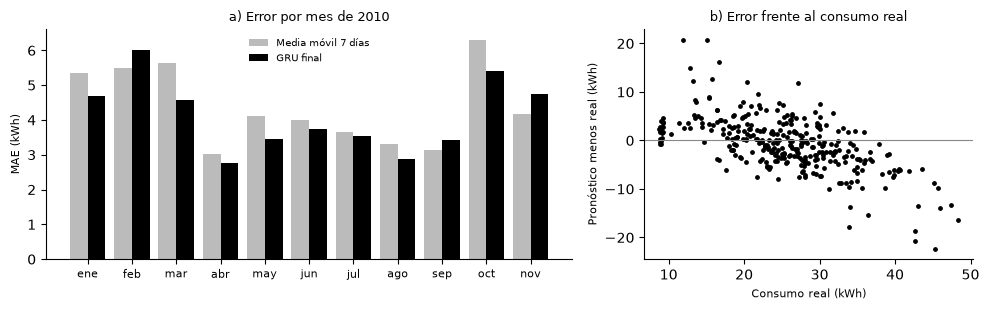

In [10]:
err = pd.DataFrame({'fecha': fechas_te, 'real': yt, 'lstm': p_ens, 'media7': modelos['Media móvil 7 días']}).set_index('fecha')
err['ae_lstm'] = (err.lstm - err.real).abs(); err['ae_media7'] = (err.media7 - err.real).abs(); err['sesgo_lstm'] = err.lstm - err.real
por_mes = err.groupby(err.index.month)[['ae_media7', 'ae_lstm', 'sesgo_lstm']].mean().round(2)
por_dia = err.groupby(err.index.dayofweek)[['ae_media7', 'ae_lstm', 'sesgo_lstm']].mean().round(2)
peores = err.sort_values('ae_lstm', ascending=False).head(10).round(2)
por_mes.to_csv(f'{SALIDA}/error_por_mes.csv'); por_dia.to_csv(f'{SALIDA}/error_por_dia.csv'); peores.to_csv(f'{SALIDA}/peores_dias.csv')
err.to_csv(f'{SALIDA}/predicciones_test.csv')
print(por_mes, por_dia, peores, sep='\n\n')
corr = np.corrcoef(err.real, err.lstm - err.real)[0, 1]; print('Correlación entre consumo real y error:', round(corr, 3))
MES = ['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago', 'sep', 'oct', 'nov']
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
x = np.arange(len(por_mes)); axs[0].bar(x - 0.2, por_mes.ae_media7, 0.4, color='#bbbbbb', label='Media móvil 7 días')
axs[0].bar(x + 0.2, por_mes.ae_lstm, 0.4, color='black', label=NOMBRE); axs[0].set_xticks(x, MES[:len(x)], fontsize=8)
axs[0].set_ylabel('MAE (kWh)', fontsize=8); axs[0].legend(fontsize=7, frameon=False); axs[0].set_title('a) Error por mes de 2010', fontsize=9)
axs[1].scatter(err.real, err.lstm - err.real, s=6, color='black'); axs[1].axhline(0, color='#888888', lw=0.8)
axs[1].set_xlabel('Consumo real (kWh)', fontsize=8); axs[1].set_ylabel('Pronóstico menos real (kWh)', fontsize=8)
axs[1].set_title('b) Error frente al consumo real', fontsize=9)
fig.tight_layout(); fig.savefig(f'{SALIDA}/fig_errores.png', dpi=200); plt.show()

In [11]:
json.dump(dict(cfg=CFG, test_por_semilla=info.to_dict('records'), versiones=dict(torch=torch.__version__, mlflow=mlflow.__version__,
          numpy=np.__version__, pandas=pd.__version__)), open(f'{SALIDA}/final.json', 'w'), indent=1, ensure_ascii=False, default=str)